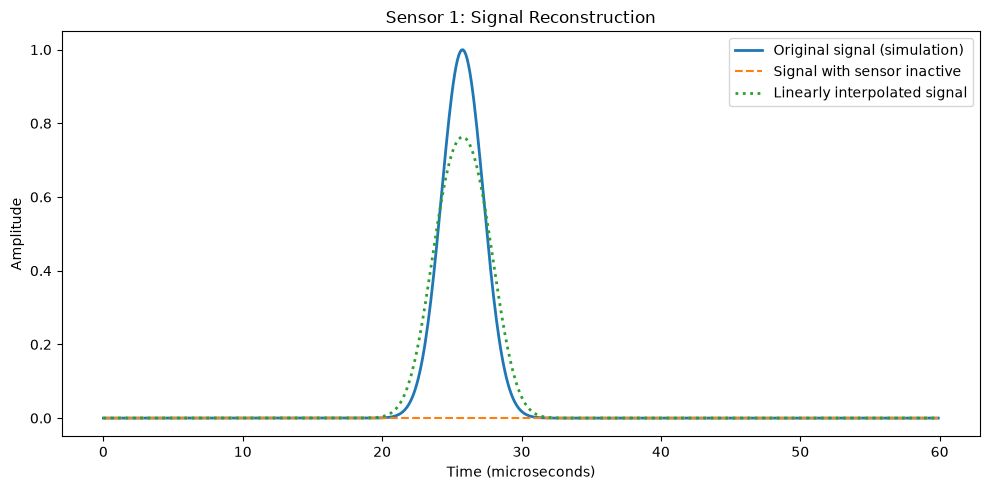

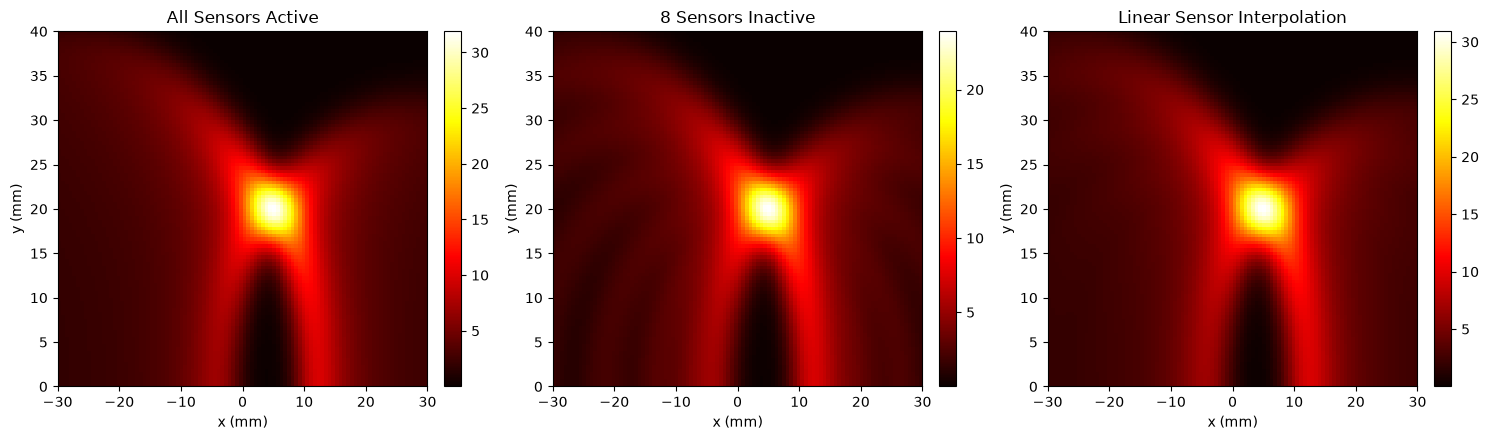

{
    "day": 30,
    "method": "Linear interpolation across sensor positions",
    "total_sensors": 32,
    "active_sensor_count": 24,
    "inactive_sensor_count": 8,
    "inactive_indices_zero_based": [
        1,
        5,
        9,
        13,
        17,
        21,
        25,
        29
    ],
    "full_sensor_baseline": {
        "peak_intensity": 31.897689381836166,
        "estimated_x_mm": 5.15151515151515,
        "estimated_y_mm": 19.797979797979796,
        "localization_error_mm": 0.2525252525252526
    },
    "inactive_without_reconstruction": {
        "peak_metrics": {
            "peak_intensity": 23.92282763019889,
            "estimated_x_mm": 5.15151515151515,
            "estimated_y_mm": 19.797979797979796,
            "localization_error_mm": 0.2525252525252526
        },
        "comparison_to_full": {
            "MAE": 1.0958713703784677,
            "RMSE": 1.519872799577488,
            "maximum_absolute_difference": 7.9748617516372775
        }
    },
  

In [1]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters
c = 1500.0
fs = 10e6
num_sensors = 32

sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

source_x = 0.005
source_y = 0.020

duration = 60e-6
time = np.arange(0, duration, 1 / fs)
dt = time[1] - time[0]

# 2. Generate synthetic sensor signals
distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)
arrival_times = distances / c

signals = np.zeros((num_sensors, len(time)))
pulse_width = 1.5e-6

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

# 3. Disable 8 sensors
inactive_indices = np.arange(1, num_sensors, 4)
active_mask = np.ones(num_sensors, dtype=bool)
active_mask[inactive_indices] = False

signals_missing = signals.copy()
signals_missing[~active_mask, :] = 0.0

# 4. Reconstruct missing sensor data using linear interpolation
# Interpolate across sensor positions separately at each time sample.
signals_reconstructed = signals_missing.copy()

for j in range(len(time)):
    signals_reconstructed[:, j] = np.interp(
        sensor_x,
        sensor_x[active_mask],
        signals_missing[active_mask, j]
    )

# 5. Image grid
image_size = 100
x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)
X, Y = np.meshgrid(x_grid, y_grid)

# 6. DAS reconstruction
def reconstruct_das(signal_matrix, sensor_mask):
    image = np.zeros(X.shape, dtype=float)

    for i in range(num_sensors):
        if not sensor_mask[i]:
            continue

        distance = np.sqrt(
            (X - sensor_x[i])**2 +
            (Y - sensor_y[i])**2
        )
        tof = distance / c

        contribution = np.interp(
            tof.ravel(),
            time,
            signal_matrix[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += contribution

    return image

# Full-sensor baseline
image_full = reconstruct_das(
    signals,
    np.ones(num_sensors, dtype=bool)
)

# Missing sensors, without reconstruction
image_missing = reconstruct_das(
    signals_missing,
    active_mask
)

# Interpolated signals, using all sensors
image_interpolated = reconstruct_das(
    signals_reconstructed,
    np.ones(num_sensors, dtype=bool)
)

# 7. Plot sensor signals before and after interpolation
plt.figure(figsize=(10, 5))

sensor_to_plot = inactive_indices[0]

plt.plot(
    time * 1e6,
    signals[sensor_to_plot],
    label="Original signal (simulation)",
    linewidth=2
)

plt.plot(
    time * 1e6,
    signals_missing[sensor_to_plot],
    "--",
    label="Signal with sensor inactive"
)

plt.plot(
    time * 1e6,
    signals_reconstructed[sensor_to_plot],
    ":",
    label="Linearly interpolated signal",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Amplitude")
plt.title(f"Sensor {sensor_to_plot}: Signal Reconstruction")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day30_sensor_interpolation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Compare reconstruction images
extent = [
    x_grid[0] * 1000, x_grid[-1] * 1000,
    y_grid[0] * 1000, y_grid[-1] * 1000
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

images = [
    (image_full, "All Sensors Active"),
    (image_missing, "8 Sensors Inactive"),
    (image_interpolated, "Linear Sensor Interpolation")
]

for ax, (img, title) in zip(axes, images):
    plot = ax.imshow(
        img,
        extent=extent,
        origin="lower",
        aspect="auto",
        cmap="hot"
    )
    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    fig.colorbar(plot, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(
    output_dir / "day30_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Quantitative metrics
def get_peak_metrics(image):
    row, col = np.unravel_index(np.argmax(image), image.shape)

    estimated_x = float(X[row, col])
    estimated_y = float(Y[row, col])

    error_mm = float(
        np.sqrt(
            (estimated_x - source_x)**2 +
            (estimated_y - source_y)**2
        ) * 1000
    )

    return {
        "peak_intensity": float(np.max(image)),
        "estimated_x_mm": estimated_x * 1000,
        "estimated_y_mm": estimated_y * 1000,
        "localization_error_mm": error_mm
    }

def compare_to_full(image):
    difference = image - image_full
    return {
        "MAE": float(np.mean(np.abs(difference))),
        "RMSE": float(np.sqrt(np.mean(difference**2))),
        "maximum_absolute_difference": float(
            np.max(np.abs(difference))
        )
    }

results = {
    "day": 30,
    "method": "Linear interpolation across sensor positions",
    "total_sensors": int(num_sensors),
    "active_sensor_count": int(np.sum(active_mask)),
    "inactive_sensor_count": int(np.sum(~active_mask)),
    "inactive_indices_zero_based": inactive_indices.tolist(),
    "full_sensor_baseline": get_peak_metrics(image_full),
    "inactive_without_reconstruction": {
        "peak_metrics": get_peak_metrics(image_missing),
        "comparison_to_full": compare_to_full(image_missing)
    },
    "linear_interpolation": {
        "peak_metrics": get_peak_metrics(image_interpolated),
        "comparison_to_full": compare_to_full(image_interpolated)
    },
    "note": (
        "Synthetic Gaussian signals. "
        "Sensor interpolation is evaluated against the full-sensor "
        "simulation baseline, which is known in this experiment."
    )
}

with open(
    output_dir / "day30_linear_interpolation_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nDay 30 completed!")
print(f"Outputs saved to: {output_dir}")
